# **Практическая работа №4. Работа с растровыми данными в Rasterio**

---

**Данные для обработки:**

- Одноканальное изображение (ЦМР): https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif
- Мультиспектральное изображение (Landsat): https://github.com/opengeos/datasets/releases/download/raster/cog.tif

### **Подготовка: импорт библиотек и загрузка данных**

Файлы скачиваются в папку с ноутбуком один раз, при повторных запусках используются локальные копии.

In [1]:
import os
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
import rasterio
import rasterio.plot
from rasterio.windows import Window
from rasterio.warp import calculate_default_transform, reproject, transform_bounds, Resampling

# Ссылки на исходные данные и имена локальных копий
DATA = {
    "dem_90m.tif": "https://github.com/opengeos/datasets/releases/download/raster/dem_90m.tif",
    "cog.tif": "https://github.com/opengeos/datasets/releases/download/raster/cog.tif",
}

for file_name, url in DATA.items():
    if not os.path.exists(file_name):
        print(f"Скачивание {file_name} ...")
        urllib.request.urlretrieve(url, file_name + ".part")  # сначала во временный файл,
        os.replace(file_name + ".part", file_name)            # чтобы не оставить недокачанный
    print(f"{file_name}: {os.path.getsize(file_name) / 2**20:.1f} МБ")

DEM_PATH = "dem_90m.tif"  # одноканальное изображение — цифровая модель рельефа (ЦМР)
MS_PATH = "cog.tif"       # мультиспектральное изображение (Cloud Optimized GeoTIFF)

print(f"\nrasterio {rasterio.__version__}, GDAL {rasterio.__gdal_version__}")

dem_90m.tif: 17.1 МБ
cog.tif: 0.6 МБ

rasterio 1.5.2, GDAL 3.12.2


### **Задание 1. Чтение и исследование растровых данных**



1. Откройте одноканальное изображение ЦМР с использованием `rasterio`.


In [2]:
# rasterio.open() не загружает растр в память целиком, а возвращает объект DatasetReader,
# через который доступны метаданные и значения пикселей
dem_src = rasterio.open(DEM_PATH)

print(dem_src)
print("Имя файла:", dem_src.name)
print("Режим    :", dem_src.mode)   # 'r' — только чтение
print("Драйвер  :", dem_src.driver)

<open DatasetReader name='dem_90m.tif' mode='r'>
Имя файла: dem_90m.tif
Режим    : r
Драйвер  : GTiff


2. Извлеките и выведите метаданные растра, включая СК, разрешение, границы, количество каналов и типы данных.


In [3]:
# Полный словарь метаданных
for key, value in dem_src.meta.items():
    print(f"{key:>9}: {value}")

crs = dem_src.crs
res_x, res_y = dem_src.res
left, bottom, right, top = dem_src.bounds
lon_min, lat_min, lon_max, lat_max = transform_bounds(crs, "EPSG:4326", *dem_src.bounds)

print("\n----- Основные характеристики -----")
print(f"Система координат : {crs} — {crs.to_wkt().split(chr(34))[1]}, "
      f"{'проекционная' if crs.is_projected else 'географическая'}, единицы: {crs.linear_units}")
print(f"Разрешение        : {res_x:.4f} × {res_y:.4f} м на пиксель")
print(f"Границы           : left={left:.1f}, bottom={bottom:.1f}, right={right:.1f}, top={top:.1f}")
print(f"Границы в градусах: долгота {lon_min:.3f}…{lon_max:.3f}, широта {lat_min:.3f}…{lat_max:.3f}")
print(f"Количество каналов: {dem_src.count}")
print(f"Типы данных       : {dem_src.dtypes}")
print(f"Значение NoData   : {dem_src.nodata}")

t = dem_src.transform
print("\nАффинное преобразование (пиксель → координаты СК):")
print(f"  a = {t.a} — ширина пикселя, e = {t.e} — высота пикселя (отрицательная: строки идут сверху вниз)")
print(f"  c = {t.c}, f = {t.f} — координаты левого верхнего угла растра")
print(f"  b = {t.b}, d = {t.d} — поворот (отсутствует)")

   driver: GTiff
    dtype: int16
   nodata: None
    width: 4269
   height: 3113
    count: 1
      crs: EPSG:3857
transform: | 90.00, 0.00,-13442488.34|
| 0.00,-90.00, 4668371.58|
| 0.00, 0.00, 1.00|

----- Основные характеристики -----
Система координат : EPSG:3857 — WGS 84 / Pseudo-Mercator, проекционная, единицы: metre
Разрешение        : 90.0000 × 89.9958 м на пиксель
Границы           : left=-13442488.3, bottom=4388214.7, right=-13058278.3, top=4668371.6
Границы в градусах: долгота -120.756…-117.305, широта 36.634…38.627
Количество каналов: 1
Типы данных       : ('int16',)
Значение NoData   : None

Аффинное преобразование (пиксель → координаты СК):
  a = 90.0 — ширина пикселя, e = -89.99579177642138 — высота пикселя (отрицательная: строки идут сверху вниз)
  c = -13442488.3428, f = 4668371.5775 — координаты левого верхнего угла растра
  b = 0.0, d = 0.0 — поворот (отсутствует)


3. Отобразите ширину и высоту растра, а также типы данных пикселей, чтобы понять размеры сетки и структуру данных.

In [4]:
width, height = dem_src.width, dem_src.height

# Читаем первый (единственный) канал в двумерный массив numpy: (строки, столбцы) = (высота, ширина)
dem = dem_src.read(1)

print(f"Ширина : {width} пикселей (столбцов)")
print(f"Высота : {height} пикселей (строк)")
print(f"Всего  : {width * height:,} пикселей".replace(",", " "))
print(f"Размер охвата: {width * res_x / 1000:.1f} × {height * res_y / 1000:.1f} км (в единицах проекции)")

print(f"\nТип данных пикселей: {dem_src.dtypes[0]} "
      f"(допустимый диапазон {np.iinfo(dem.dtype).min}…{np.iinfo(dem.dtype).max})")
print(f"Массив numpy: shape={dem.shape}, dtype={dem.dtype}, объём {dem.nbytes / 2**20:.1f} МБ")
print(f"Высоты: min={dem.min()} м, max={dem.max()} м, среднее={dem.mean():.1f} м")

Ширина : 4269 пикселей (столбцов)
Высота : 3113 пикселей (строк)
Всего  : 13 289 397 пикселей
Размер охвата: 384.2 × 280.2 км (в единицах проекции)

Тип данных пикселей: int16 (допустимый диапазон -32768…32767)
Массив numpy: shape=(3113, 4269), dtype=int16, объём 25.3 МБ
Высоты: min=15 м, max=4338 м, среднее=1582.3 м


**Итог задания 1.** ЦМР — одноканальный GeoTIFF 4269 × 3113 пикселей (≈ 13,3 млн), тип `int16` (целые значения высоты в метрах, 2 байта на пиксель). СК — EPSG:3857 (WGS 84 / Pseudo-Mercator), пиксель 90 × 90 м в единицах проекции. Охват — 384 × 280 км в метрах проекции, или 120,76…117,30° з. д. и 36,63…38,63° с. ш. (Калифорния, хребет Сьерра-Невада). Высоты от 15 до 4338 м; NoData не задано, и заполнителей пропусков в данных нет (минимум — 15 м).

Массив numpy имеет форму `(строки, столбцы)` = `(высота, ширина)`, т. е. размеры идут в обратном порядке по сравнению с `width × height`.

---



### **Задание 2. Визуализация и манипулирование растровыми каналами**



1. Визуализируйте одноканальное изображение ЦМР с использованием пользовательской цветовой карты (например, cmap='terrain').


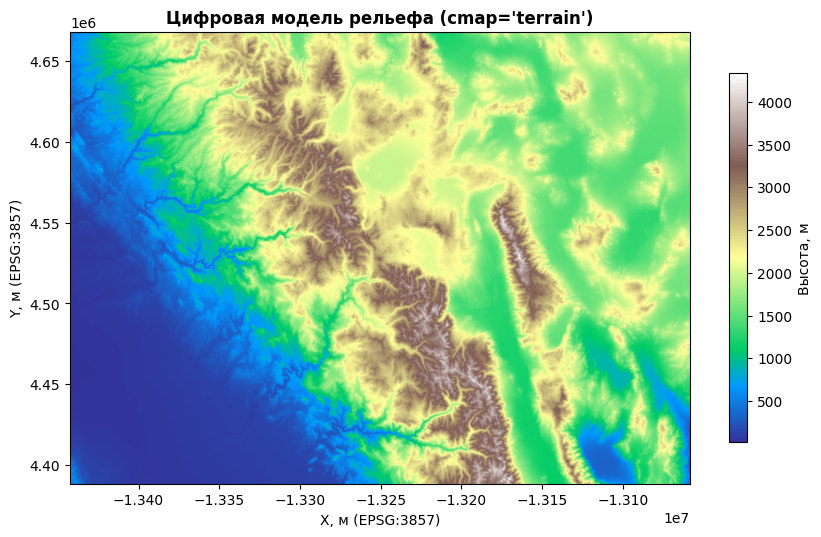

In [5]:
fig, ax = plt.subplots(figsize=(10, 8))

# rasterio.plot.show учитывает геопривязку: оси подписаны в координатах СК растра (метры EPSG:3857)
rasterio.plot.show(dem, transform=dem_src.transform, ax=ax, cmap="terrain",
                   title="Цифровая модель рельефа (cmap='terrain')")
fig.colorbar(ax.get_images()[0], ax=ax, label="Высота, м", shrink=0.6)
ax.set_xlabel("X, м (EPSG:3857)")
ax.set_ylabel("Y, м (EPSG:3857)")
plt.show()

Низины (Центральная долина Калифорнии, слева внизу) окрашены в синие и зелёные тона, хребет Сьерра-Невада по диагонали — в коричневые, вершины выше 4000 м — в белый. Оси подписаны в метрах EPSG:3857, потому что `rasterio.plot.show` использует геопривязку растра (`transform`).

2. Откройте мультиспектральное изображение и визуализируйте первый канал с использованием подходящей цветовой карты.


<open DatasetReader name='cog.tif' mode='r'>
Размер : 343 × 206 пикселей, каналов: 4, тип: float64
СК     : EPSG:4326, разрешение 8.98e-05° (≈ 10 м)
Границы: BoundingBox(left=6.860074498707138, bottom=53.39783678168941, right=6.890886712952438, top=53.41634207654228)


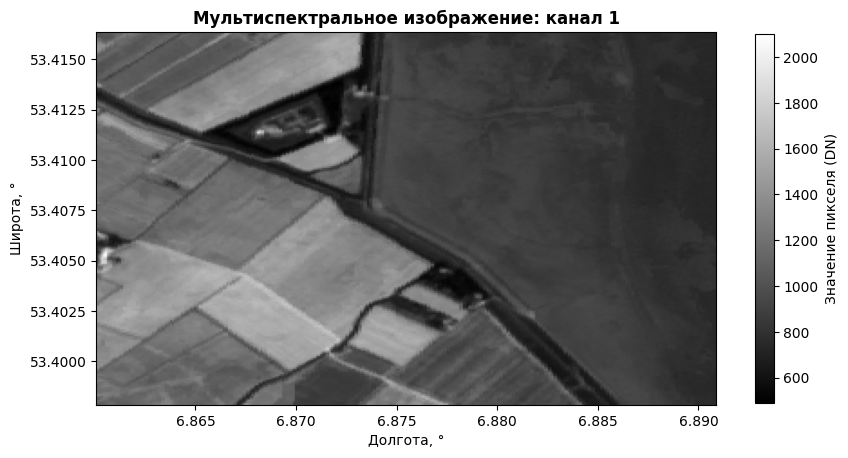

In [6]:
ms_src = rasterio.open(MS_PATH)

print(ms_src)
print(f"Размер : {ms_src.width} × {ms_src.height} пикселей, каналов: {ms_src.count}, тип: {ms_src.dtypes[0]}")
print(f"СК     : {ms_src.crs}, разрешение {ms_src.res[0]:.2e}° (≈ {ms_src.res[0] * 111_320:.0f} м)")
print(f"Границы: {ms_src.bounds}")

# Для одного спектрального канала подходит шкала серого: чем светлее пиксель, тем выше отражение
fig, ax = plt.subplots(figsize=(10, 6))
rasterio.plot.show((ms_src, 1), ax=ax, cmap="gray", title="Мультиспектральное изображение: канал 1")
fig.colorbar(ax.get_images()[0], ax=ax, label="Значение пикселя (DN)", shrink=0.8)
ax.set_xlabel("Долгота, °")
ax.set_ylabel("Широта, °")
plt.show()

#### **Порядок каналов в `cog.tif`**

В файле не заданы описания каналов, а для заданий 2.3 и 4 нужно знать, где Red, Green, Blue и NIR. Пиксель ≈ 10 м, каналов четыре — по-видимому, это 10-метровые каналы Sentinel-2 (синий, зелёный, красный, ближний ИК). Порядок определим по спектральным свойствам:

- канал 4 выделяется диапазоном значений (до ~4300) — это **NIR**: растительность сильно отражает ближний ИК, а вода почти полностью его поглощает;
- среди видимых каналов у растительности **красный** — самый тёмный (поглощение хлорофиллом), а **синий** на снимках без атмосферной коррекции самый яркий из-за рассеяния в атмосфере.

Сравним средние значения каналов на заведомой растительности (NIR > 3000) и воде (NIR < 500):

In [7]:
print("Описания каналов в файле:", ms_src.descriptions)

ms_data = ms_src.read()      # все каналы: массив (каналы, строки, столбцы)
vegetation = ms_data[3] > 3000
water = ms_data[3] < 500

print(f"\n{'Канал':<6}{'min':>7}{'max':>7}{'среднее':>9} │{'растительность':>15}{'вода':>7}")
for i, band in enumerate(ms_data, start=1):
    print(f"{i:<6}{band.min():>7.0f}{band.max():>7.0f}{band.mean():>9.0f} │"
          f"{band[vegetation].mean():>15.0f}{band[water].mean():>7.0f}")
print(f"\nДоля пикселей: растительность {vegetation.mean():.1%}, вода {water.mean():.1%}")

Описания каналов в файле: (None, None, None, None)

Канал     min    max  среднее │ растительность   вода
1         488   2102     1021 │            908    777
2         735   1960     1132 │           1132    975
3         914   2083     1248 │           1194   1124
4         336   4269     1673 │           3360    402

Доля пикселей: растительность 13.5%, вода 15.1%


**Вывод.** И на растительности, и на воде канал 1 — самый тёмный из видимых, а канал 3 — самый яркий (908 < 1132 < 1194 и 777 < 975 < 1124). Канал 4 на растительности достигает ~3360, а на воде падает до ~400. Порядок каналов: **1 — Red, 2 — Green, 3 — Blue, 4 — NIR**. Это подтверждает и композит ниже: в комбинации 1-2-3 цвета естественные (трава на дамбе зелёная, пашни бурые).

Диапазоны каналов сильно различаются (максимум NIR — 4269, видимых каналов — около 2000), поэтому перед совмещением каждый канал нормализуется отдельно.

3. Объедините несколько каналов из мультиспектрального изображения (например, Красный, Зеленый и Синий) и совместите их в один массив для создания RGB-композитного изображения.

>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

Диапазон без нормализации: 488.0 … 2102.0
RGB-композит: (206, 343, 3) float64 диапазон 0.0 … 1.0


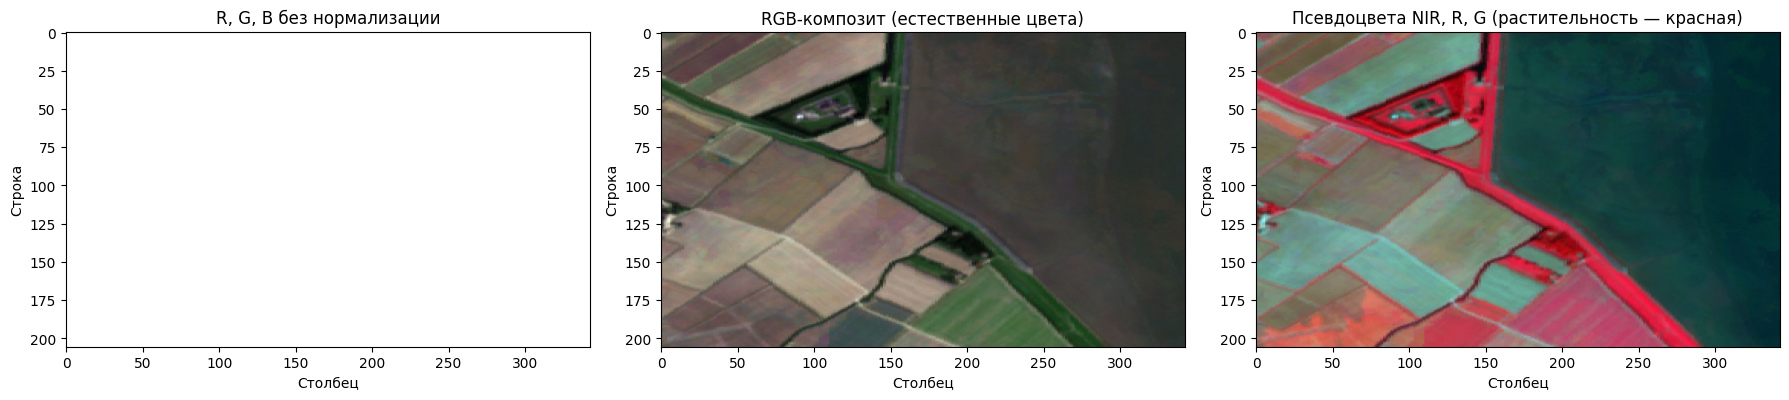

In [8]:
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm


# Номера каналов (см. определение порядка каналов выше)
RED, GREEN, BLUE, NIR = 1, 2, 3, 4

red = ms_src.read(RED)
green = ms_src.read(GREEN)
blue = ms_src.read(BLUE)
nir = ms_src.read(NIR)

# Совмещаем каналы в один массив (строки, столбцы, 3) — формат, который ожидает plt.imshow
rgb_raw = np.dstack((red, green, blue))                                  # без нормализации
rgb = np.dstack((normalize(red), normalize(green), normalize(blue)))     # естественные цвета
false_color = np.dstack((normalize(nir), normalize(red), normalize(green)))  # NIR-R-G

print("Диапазон без нормализации:", rgb_raw.min(), "…", rgb_raw.max())
print("RGB-композит:", rgb.shape, rgb.dtype, "диапазон", rgb.min(), "…", rgb.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
axes[0].imshow(rgb_raw.clip(0, 1))   # значения ≫ 1 обрезаются до 1 → белое изображение
axes[0].set_title("R, G, B без нормализации")
axes[1].imshow(rgb)
axes[1].set_title("RGB-композит (естественные цвета)")
axes[2].imshow(false_color)
axes[2].set_title("Псевдоцвета NIR, R, G (растительность — красная)")
for ax in axes:
    ax.set_xlabel("Столбец")
    ax.set_ylabel("Строка")
plt.tight_layout()
plt.show()

Без нормализации значения пикселей (488…2102) намного больше 1, `imshow` обрезает их до 1, и изображение получается белым. После нормализации каждого канала в диапазон [0, 1] виден снимок северо-востока Нидерландов: поля, поросшая травой дамба вдоль берега и приливная акватория Ваддензее справа. На композите NIR-R-G растительность ярко-красная (сильно отражает ближний ИК), а вода тёмная (поглощает его).

---



### **Задание 3. Обрезка растра с использованием индексации массива**



1. Откройте мультиспектральное изображение и обрежьте его с использованием спискового среза (указав диапазоны строк и столбцов).


In [9]:
with rasterio.open(MS_PATH) as src:
    data = src.read()            # (каналы, строки, столбцы)
    ms_crs = src.crs
    ms_transform = src.transform

print("Исходный массив:", data.shape)

# Диапазоны строк и столбцов для обрезки (как в срезах Python: начало включается, конец — нет)
row_start, row_stop = 20, 170
col_start, col_stop = 80, 280

# Списковый срез: все каналы, выбранные строки и столбцы
subset = data[:, row_start:row_stop, col_start:col_stop]

print(f"Строки {row_start}:{row_stop}, столбцы {col_start}:{col_stop}")
print("Обрезанный массив:", subset.shape, subset.dtype)

Исходный массив: (4, 206, 343)
Строки 20:170, столбцы 80:280
Обрезанный массив: (4, 150, 200) float64


2. Визуализируйте обрезанную часть изображения с использованием matplotlib, чтобы убедиться в корректном результате.


>*Примечание:*
>
> При работе с многоканальными растровыми изображениями, особенно в формате COG.TIFF (Cloud Optimized GeoTIFF), может возникнуть проблема с некорректным отображением псевдоцветного изображения. Это связано с тем, что разные каналы могут иметь различные диапазоны значений пикселей.
>
> Для корректной визуализации на шаге 2 необходимо применить нормализацию к каждому каналу перед отображением.



Включите следующую функцию в ваш код:

```python
# Функция для нормализации канала в диапазон от 0 до 1
def normalize(band):
    band_min = band.min()
    band_max = band.max()
    band_norm = (band - band_min) / (band_max - band_min)
    return band_norm
```

RGB фрагмента: (150, 200, 3)


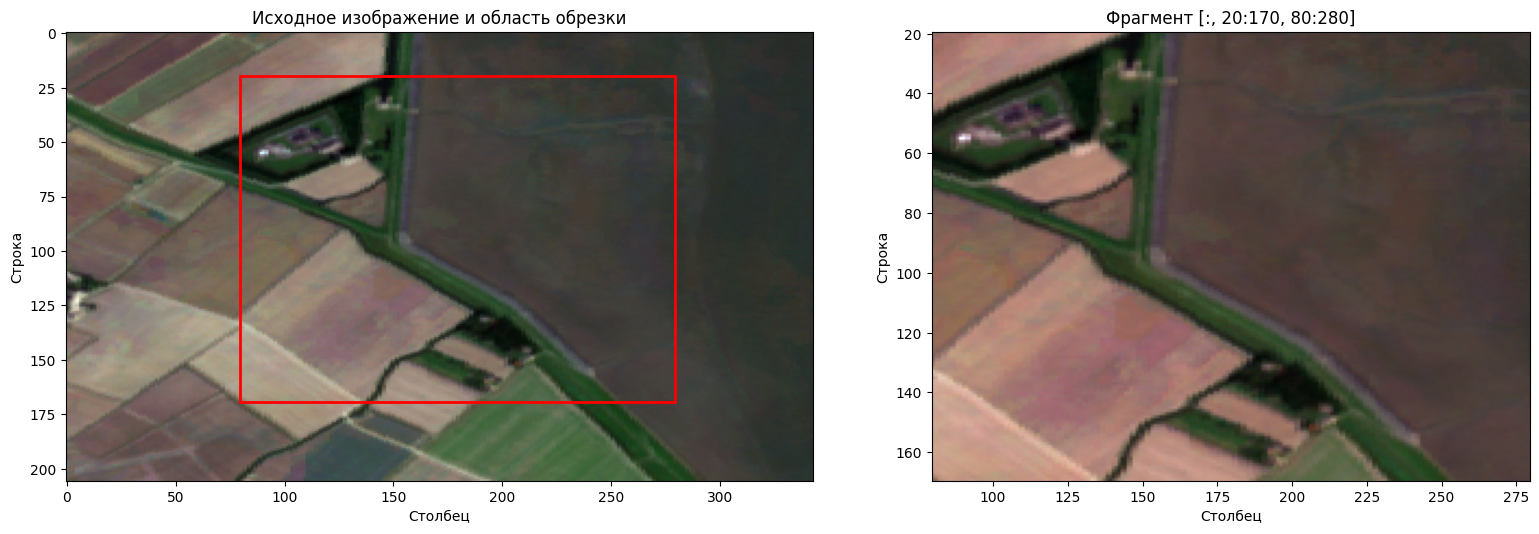

In [10]:
# Нормализуем каждый канал фрагмента (функция normalize объявлена в задании 2.3)
rgb_subset = np.dstack((normalize(subset[RED - 1]),
                        normalize(subset[GREEN - 1]),
                        normalize(subset[BLUE - 1])))
print("RGB фрагмента:", rgb_subset.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [343 / 206, 200 / 150]})

# Слева — всё изображение с рамкой области обрезки
axes[0].imshow(rgb)
axes[0].add_patch(Rectangle((col_start - 0.5, row_start - 0.5), col_stop - col_start, row_stop - row_start,
                            edgecolor="red", facecolor="none", linewidth=2))
axes[0].set_title("Исходное изображение и область обрезки")

# Справа — обрезанный фрагмент; extent сохраняет номера строк/столбцов исходного растра
axes[1].imshow(rgb_subset, extent=(col_start - 0.5, col_stop - 0.5, row_stop - 0.5, row_start - 0.5))
axes[1].set_title(f"Фрагмент [:, {row_start}:{row_stop}, {col_start}:{col_stop}]")

for ax in axes:
    ax.set_xlabel("Столбец")
    ax.set_ylabel("Строка")
plt.tight_layout()
plt.show()

3. Сохраните обрезанное подмножество растра в новый файл с именем `clipped_multispectral.tif`.

In [11]:
CLIP_PATH = "clipped_multispectral.tif"

# Окно, соответствующее срезу, и геопривязка фрагмента: начало координат сдвигается в его левый верхний угол
window = Window.from_slices((row_start, row_stop), (col_start, col_stop))
clip_transform = rasterio.windows.transform(window, ms_transform)

with rasterio.open(
    CLIP_PATH,
    "w",
    driver="GTiff",
    height=subset.shape[1],
    width=subset.shape[2],
    count=subset.shape[0],
    dtype=subset.dtype,
    crs=ms_crs,
    transform=clip_transform,
    compress="lzw",
) as dst:
    dst.write(subset)   # сохраняются исходные (не нормализованные) значения всех каналов

# Проверка: читаем сохранённый файл обратно
with rasterio.open(CLIP_PATH) as chk:
    print(f"Файл {CLIP_PATH}: {chk.width} × {chk.height} пикс., каналов {chk.count}, {chk.dtypes[0]}, {chk.crs}")
    print("Границы фрагмента:", chk.bounds)
    print("Ожидаемые границы:", rasterio.windows.bounds(window, ms_transform))
    print("Данные совпадают с срезом:", np.array_equal(chk.read(), subset))

Файл clipped_multispectral.tif: 200 × 150 пикс., каналов 4, float64, EPSG:4326
Границы фрагмента: BoundingBox(left=6.867261020980094, bottom=53.40107071671225, right=6.885227326662484, top=53.41454544597404)
Ожидаемые границы: (6.867261020980094, 53.40107071671225, 6.885227326662484, 53.41454544597404)
Данные совпадают с срезом: True


**Итог задания 3.** Срез `data[:, 20:170, 80:280]` выделяет фрагмент 200 × 150 пикселей со всеми четырьмя каналами. Чтобы сохранённый фрагмент оказался на своём месте на карте, пересчитана геопривязка: `rasterio.windows.transform` переносит начало координат в левый верхний угол окна (столбец 80, строка 20), размер пикселя не меняется. Без этого фрагмент «съехал» бы в левый верхний угол исходного снимка. Проверка подтверждает: границы файла совпадают с ожидаемыми, а данные — со срезом.

В файл записаны исходные значения: нормализация нужна только для отображения.

---



### **Задание 4. Вычисление NDWI (калькуляция каналов)**



1. Откройте мультиспектральное изображение и извлеките каналы Green (Зеленый) и Ближний инфракрасный (NIR).


In [12]:
with rasterio.open(MS_PATH) as src:
    green = src.read(GREEN).astype("float64")   # канал 2 — Green
    nir = src.read(NIR).astype("float64")       # канал 4 — NIR
    ms_profile = src.profile                    # профиль понадобится для сохранения NDWI

for name, band in (("Green", green), ("NIR", nir)):
    print(f"{name:>5}: shape={band.shape}, min={band.min():.0f}, max={band.max():.0f}, среднее={band.mean():.0f}")

Green: shape=(206, 343), min=735, max=1960, среднее=1132
  NIR: shape=(206, 343), min=336, max=4269, среднее=1673


2. Вычислите Нормализованный разностный водный индекс ([NDWI](https://en.wikipedia.org/wiki/Normalized_difference_water_index)) по формуле:

    NDWI = (Green - NIR) / (Green + NIR)

In [13]:
denominator = green + nir

# Защита от деления на ноль: там, где Green + NIR = 0, индекс не определён (NaN)
with np.errstate(divide="ignore", invalid="ignore"):
    ndwi = np.where(denominator != 0, (green - nir) / denominator, np.nan)

print(f"NDWI: min={np.nanmin(ndwi):.3f}, max={np.nanmax(ndwi):.3f}, среднее={np.nanmean(ndwi):.3f}")
print(f"Пикселей с NDWI > 0 (вода): {(ndwi > 0).mean():.1%}")

NDWI: min=-0.622, max=0.477, среднее=-0.063
Пикселей с NDWI > 0 (вода): 41.2%


3. Визуализируйте результат NDWI с использованием цветовой карты, подходящей для воды (например, cmap='Blues'), чтобы выделить водные объекты.


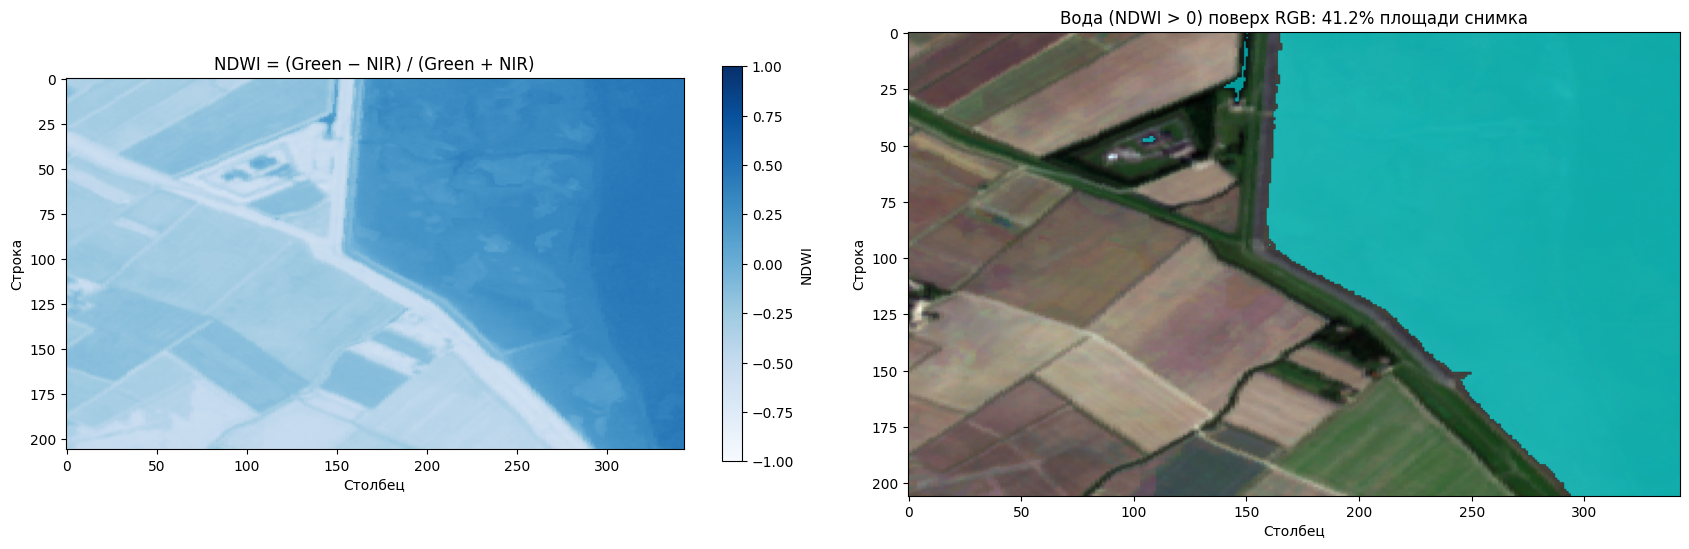

In [14]:
water_mask = ndwi > 0   # классический порог NDWI (McFeeters): положительные значения — вода

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))

im = axes[0].imshow(ndwi, cmap="Blues", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], label="NDWI", shrink=0.85)
axes[0].set_title("NDWI = (Green − NIR) / (Green + NIR)")

# Маска воды поверх RGB-композита
axes[1].imshow(rgb)
axes[1].imshow(np.ma.masked_where(~water_mask, water_mask), cmap=ListedColormap(["cyan"]), alpha=0.6)
axes[1].set_title(f"Вода (NDWI > 0) поверх RGB: {water_mask.mean():.1%} площади снимка")

for ax in axes:
    ax.set_xlabel("Столбец")
    ax.set_ylabel("Строка")
plt.tight_layout()
plt.show()

Вода отражает зелёный свет сильнее, чем ближний ИК, поэтому у воды NDWI > 0, а у растительности и почвы NDWI < 0. Тёмно-синим выделяется акватория справа (у правого края снимка NDWI ≈ 0,4, максимум 0,48) и два небольших водоёма у дамбы и построек. Светлее всего поросшая травой дамба (минимум −0,62). Порог 0 относит к воде 41 % снимка: акваторию вместе с мокрой приливной отмелью. Средний NDWI воды — 0,30, суши — −0,32.



4. Сохраните полученное изображение NDWI как новый растровый файл с именем ndwi.tif.

In [15]:
NDWI_PATH = "ndwi.tif"

# Профиль исходного снимка (СК, геопривязка, размер) с поправками: один канал float32, сжатие, nodata
ndwi_profile = ms_profile.copy()
ndwi_profile.update(count=1, dtype=rasterio.float32, nodata=np.nan, compress="lzw")

with rasterio.open(NDWI_PATH, "w", **ndwi_profile) as dst:
    dst.write(ndwi.astype(rasterio.float32), 1)

with rasterio.open(NDWI_PATH) as chk:
    saved = chk.read(1)
    print(f"Файл {NDWI_PATH}: {chk.width} × {chk.height} пикс., каналов {chk.count}, {chk.dtypes[0]}, {chk.crs}")
    print("Геопривязка совпадает с исходной:", chk.transform == ms_profile["transform"])
    print(f"Диапазон значений: {np.nanmin(saved):.3f} … {np.nanmax(saved):.3f}")

Файл ndwi.tif: 343 × 206 пикс., каналов 1, float32, EPSG:4326
Геопривязка совпадает с исходной: True
Диапазон значений: -0.622 … 0.477


---



### **Задание 5. Перепроецирование растровых данных**



1. Перепроецируйте одноканальный растр ЦМР из его исходной СК в EPSG:4326 (WGS 84) с использованием функции `rasterio.warp.reproject`.


In [16]:
DST_CRS = "EPSG:4326"    # целевая СК — WGS 84, географические координаты (градусы)
DEM_NODATA = -32768      # «нет данных» для пикселей новой сетки, не покрытых исходным растром

with rasterio.open(DEM_PATH) as src:
    # Параметры новой сетки: аффинное преобразование и размер в пикселях
    dst_transform, dst_width, dst_height = calculate_default_transform(
        src.crs, DST_CRS, src.width, src.height, *src.bounds
    )

    # Массив под результат, заранее заполненный значением nodata
    dem_4326 = np.full((dst_height, dst_width), DEM_NODATA, dtype=src.dtypes[0])

    reproject(
        source=rasterio.band(src, 1),
        destination=dem_4326,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=dst_transform,
        dst_crs=DST_CRS,
        dst_nodata=DEM_NODATA,
        resampling=Resampling.bilinear,  # билинейная интерполяция — для непрерывной величины (высоты)
    )
    dem_profile = src.profile.copy()
    src_crs, src_res = src.crs, src.res

valid = dem_4326 != DEM_NODATA

print(f"СК        : {src_crs} → {DST_CRS}")
print(f"Размер    : {dem.shape[1]} × {dem.shape[0]} → {dst_width} × {dst_height} пикселей")
print(f"Разрешение: {src_res[0]:.2f} × {src_res[1]:.2f} м → {dst_transform.a:.6f} × {-dst_transform.e:.6f}°")
print(f"Пикселей без данных: {(~valid).sum()}")
print(f"Высоты до : {dem.min()}…{dem.max()} м, среднее {dem.mean():.1f} м")
print(f"Высоты после: {dem_4326[valid].min()}…{dem_4326[valid].max()} м, среднее {dem_4326[valid].mean():.1f} м")

СК        : EPSG:3857 → EPSG:4326
Размер    : 4269 × 3113 → 4575 × 2642 пикселей
Разрешение: 90.00 × 90.00 м → 0.000754 × 0.000754°
Пикселей без данных: 0
Высоты до : 15…4338 м, среднее 1582.3 м
Высоты после: 19…4319 м, среднее 1580.1 м


2. Сохраните перепроецированный растр в новый файл GeoTIFF с именем `reprojected_dem.tif`.


In [17]:
REPROJ_PATH = "reprojected_dem.tif"

dem_profile.update(crs=DST_CRS, transform=dst_transform, width=dst_width, height=dst_height,
                   nodata=DEM_NODATA)

with rasterio.open(REPROJ_PATH, "w", **dem_profile) as dst:
    dst.write(dem_4326, 1)

with rasterio.open(REPROJ_PATH) as chk:
    print(f"Файл {REPROJ_PATH}: {os.path.getsize(REPROJ_PATH) / 2**20:.1f} МБ")
    print(f"СК: {chk.crs}, размер {chk.width} × {chk.height}, разрешение {chk.res[0]:.6f}°, тип {chk.dtypes[0]}")
    print("Границы:", chk.bounds)
    print("Данные совпадают:", np.array_equal(chk.read(1), dem_4326))

Файл reprojected_dem.tif: 12.8 МБ
СК: EPSG:4326, размер 4575 × 2642, разрешение 0.000754°, тип int16
Границы: BoundingBox(left=-120.75592734935736, bottom=36.63399062180265, right=-117.30487980330712, top=38.62692343418839)
Данные совпадают: True


3. Визуализируйте как исходный, так и перепроецированный наборы данных ЦМР, чтобы сравнить, как перепроецирование влияет на пространственное покрытие и разрешение.

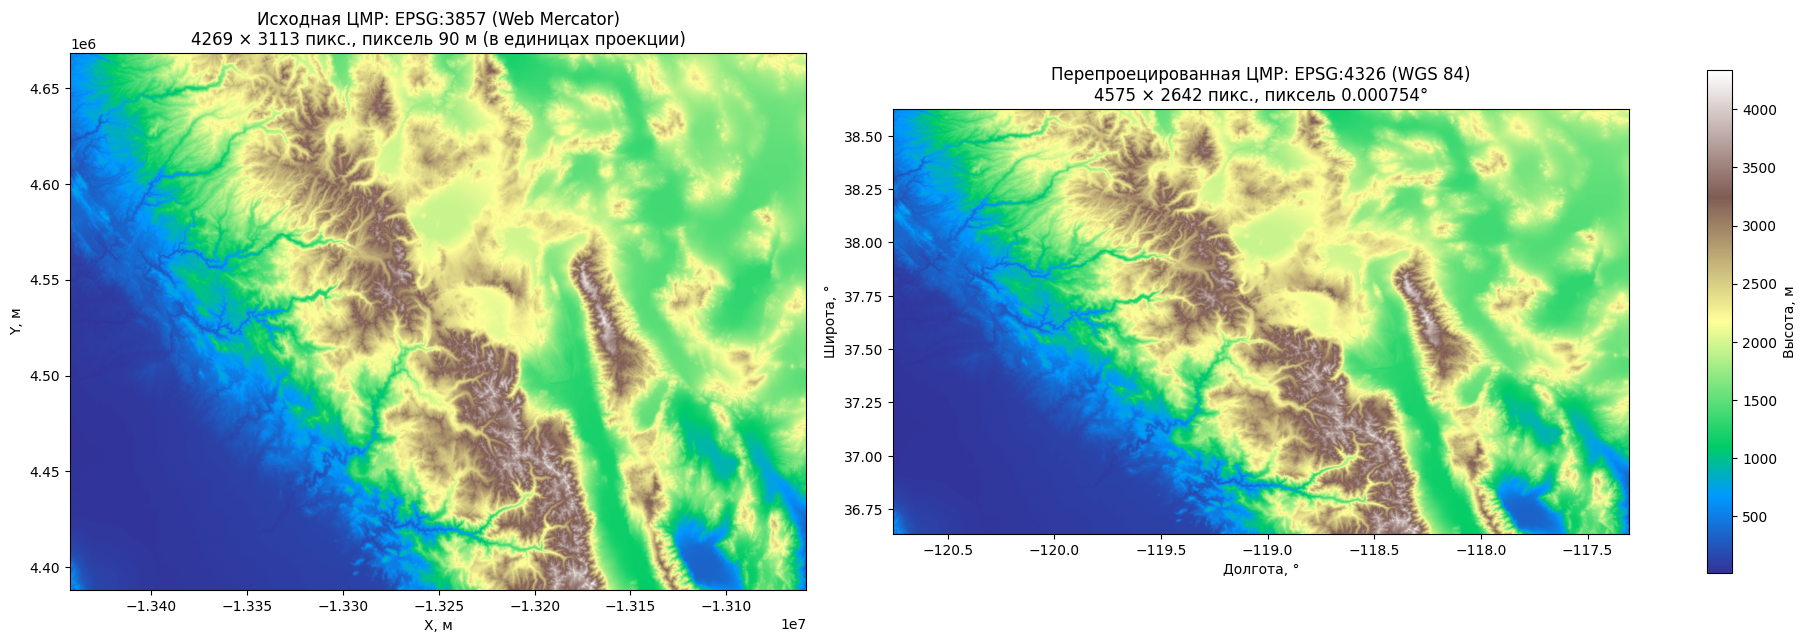

                                      EPSG:3857 (исходный)         EPSG:4326 (новый)
Размер, пикселей                               4269 × 3113               4575 × 2642
Всего пикселей                                   13.29 млн                 12.09 млн
Разрешение (единицы СК)                      90.0 × 90.0 м      0.000754 × 0.000754°
Пиксель на местности (В-З × С-Ю)*              ≈ 71 × 71 м               ≈ 67 × 84 м
Долгота охвата                          -120.756…-117.305°        -120.756…-117.305°
Широта охвата                               36.634…38.627°            36.634…38.627°
Ширина / высота на графике                            1.37                      1.73

* на средней широте 37.63°; масштаб Меркатора здесь 1 / cos φ = 1.263


In [18]:
vmin, vmax = dem.min(), dem.max()   # общая шкала высот для обоих растров
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), layout="constrained")

rasterio.plot.show(dem, transform=dem_src.transform, ax=axes[0], cmap="terrain", vmin=vmin, vmax=vmax)
axes[0].set_title(f"Исходная ЦМР: EPSG:3857 (Web Mercator)\n"
                  f"{dem.shape[1]} × {dem.shape[0]} пикс., пиксель {src_res[0]:.0f} м (в единицах проекции)")
axes[0].set_xlabel("X, м")
axes[0].set_ylabel("Y, м")

rasterio.plot.show(np.ma.masked_equal(dem_4326, DEM_NODATA), transform=dst_transform, ax=axes[1],
                   cmap="terrain", vmin=vmin, vmax=vmax)
axes[1].set_title(f"Перепроецированная ЦМР: EPSG:4326 (WGS 84)\n"
                  f"{dst_width} × {dst_height} пикс., пиксель {dst_transform.a:.6f}°")
axes[1].set_xlabel("Долгота, °")
axes[1].set_ylabel("Широта, °")

fig.colorbar(axes[1].get_images()[0], ax=axes, label="Высота, м", shrink=0.8)
plt.show()

# ---- Количественное сравнение охвата и разрешения ----
M_PER_DEG = 111_320                                   # длина 1° меридиана, м (приближённо)
src_b = dem_src.bounds
src_b_deg = transform_bounds(dem_src.crs, DST_CRS, *src_b)
dst_b = rasterio.transform.array_bounds(dst_height, dst_width, dst_transform)
lat_c = (dst_b[1] + dst_b[3]) / 2                     # средняя широта территории
k = np.cos(np.deg2rad(lat_c))                         # масштабный множитель Меркатора на этой широте
res_deg = dst_transform.a

table = [
    ("", "EPSG:3857 (исходный)", "EPSG:4326 (новый)"),
    ("Размер, пикселей", f"{dem.shape[1]} × {dem.shape[0]}", f"{dst_width} × {dst_height}"),
    ("Всего пикселей", f"{dem.size / 1e6:.2f} млн", f"{dem_4326.size / 1e6:.2f} млн"),
    ("Разрешение (единицы СК)", f"{src_res[0]:.1f} × {src_res[1]:.1f} м", f"{res_deg:.6f} × {res_deg:.6f}°"),
    ("Пиксель на местности (В-З × С-Ю)*", f"≈ {src_res[0] * k:.0f} × {src_res[1] * k:.0f} м",
     f"≈ {res_deg * M_PER_DEG * k:.0f} × {res_deg * M_PER_DEG:.0f} м"),
    ("Долгота охвата", f"{src_b_deg[0]:.3f}…{src_b_deg[2]:.3f}°", f"{dst_b[0]:.3f}…{dst_b[2]:.3f}°"),
    ("Широта охвата", f"{src_b_deg[1]:.3f}…{src_b_deg[3]:.3f}°", f"{dst_b[1]:.3f}…{dst_b[3]:.3f}°"),
    ("Ширина / высота на графике", f"{(src_b.right - src_b.left) / (src_b.top - src_b.bottom):.2f}",
     f"{(dst_b[2] - dst_b[0]) / (dst_b[3] - dst_b[1]):.2f}"),
]
for name, a, b in table:
    print(f"{name:<34}{a:>24}{b:>26}")
print(f"\n* на средней широте {lat_c:.2f}°; масштаб Меркатора здесь 1 / cos φ = {1 / k:.3f}")

**Сравнение исходной и перепроецированной ЦМР**

- **Пространственное покрытие** не изменилось: обе ЦМР охватывают 120,76…117,30° з. д. и 36,63…38,63° с. ш., пикселей без данных нет. Переход из Меркатора в широту/долготу переводит прямоугольник в прямоугольник (X зависит только от долготы, Y — только от широты), поэтому пустых углов не возникает.
- **Форма изображения** разная. В Web Mercator отношение сторон 1,37 соответствует реальной форме территории (проекция равноугольная). В EPSG:4326 оно равно 1,73: на широте ~37,6° градус долготы короче градуса широты в 1/cos φ ≈ 1,26 раза, а на графике оба градуса одинаковой длины, поэтому рельеф растянут по горизонтали.
- **Разрешение.** 90 м в EPSG:3857 — это метры проекции. На этой широте пиксель на местности ≈ 71 × 71 м. После перепроецирования пиксель квадратный в градусах (0,000754°), но на местности прямоугольный: ≈ 67 м с запада на восток и ≈ 84 м с севера на юг. `calculate_default_transform` подобрал сетку 4575 × 2642 (12,1 млн пикселей вместо 13,3 млн): по долготе пикселей стало больше, по широте — меньше.
- **Значения** пересчитаны билинейной интерполяцией: диапазон высот 15…4338 м превратился в 19…4319 м (экстремумы немного сглаживаются), среднее почти не изменилось (1582,3 → 1580,1 м). Чтобы сохранить исходные значения без изменений, используют `Resampling.nearest`, но для непрерывной величины, такой как высота, билинейная интерполяция даёт более гладкий результат.

---